# Preloaded Bolted Joint Analysis - Rev C

Victor J. Marrero
Supersedes the bolted-joint sections of `MachanicalEngineeringNotebookRevB.ipynb`.

**References**
1. Chambers, J.A., *Preloaded Joint Analysis Methodology for Space Flight Systems*, NASA TM-106943, 1995.
2. *Guideline for Bolted Joint Design and Analysis*, Version 1.0.
3. 540-PG-8072.1.2B, *Mechanical Fastener Torque Guidelines*.

**Units** - inches, lbf, psi, degF throughout. No mixed-unit inputs.

**What changed from Rev B**

| # | Rev B | Rev C |
|---|-------|-------|
| 1 | Tension/shear allowables used the *thread shear* area `5*pi*Le*D_min/8` | Tensile stress area `At` |
| 2 | `MS = np.max(P_ult)/P_b - 1` for insert pull-out | `min` of the three modes |
| 3 | `Stress = P_b * A` | `P_b / A` |
| 4 | `P_b = P_min + P_external` | `P_b = Po_max + P_thermal + n*phi*SF*P_et` |
| 5 | `TensionSafetyFactor` defined but unused | SF applied to external loads only, everywhere |
| 6 | `n` was both loading-plane factor and threads/inch | no shared globals; explicit arguments |
| 7 | `Fty` in `Rt`, `Fsu` in `Rs` (mixed bases) | yield and ultimate evaluated separately |
| 8 | `Fsu = 0.75*Ftu` | 0.55-0.60*Ftu; `Fsy = 0.577*Fty` |
| 9 | `np.round(At, 3)` (8% error on a #2) | no rounding |
| 10 | `P_relax` commented out; 3 different uncertainty values | one `Preload` object: `Po_max`, `Po_min`, `P_relax` |
| 11 | Thermal back-solved into a fake "external load" | thermal is its own term, signed per Guideline sec. 7 |
| 12 | Separation SF = 1.25, wrong `P_sep` | 1.2 structural / 1.4 pressure, `P_sep = (1-n*phi)*P_et` |
| 13 | Insert modes reused bolt `D_min` and `Le` | each mode uses its own mating geometry |
| 14 | Configs 2 and 4 crash (`layersThickness[nx]`, `Bolt[3]`) | fixed and guarded |
| 15 | Single equivalent-modulus member stiffness | Shigley frustum stack, layer by layer (optional) |
| 16 | One temperature case | hot / cold / ambient envelope, worst per mode |


## 1. Setup

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root on the path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from boltjoint import (
    Fastener, Joint, Layer, Preload, JointAnalysis, LoadCase,
    InsertSpec, AbutmentSpec, materials, margins as M,
    min_engagement_equal_strength,
    preload_from_torque, preload_from_yield_fraction, preload_target,
    ThermalEnvironment, run_thermal_envelope,
    NUT_FACTOR, UNCERTAINTY,
)

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("boltjoint ready")

boltjoint ready


## 2. User input

Everything the analysis needs is in this one cell. No other cell should be edited
for a routine run.

**Configurations** (TM-106943 figs. 7-10)
1. through-bolt + nut, protruding head
2. through-bolt + nut, 100 deg flat head
3. bolt into threaded insert / tapped hole, protruding head
4. bolt into threaded insert / tapped hole, flat head


In [2]:
# ---------------- fastener ----------------
THREAD          = "2-56"           # see boltjoint.fasteners.THREADS
HEAD_STYLE      = "socket"         # 'socket' | 'flat100'
SHANK_DIA       = None             # None = full thread; set for reduced shank
BOLT_MATERIAL   = "A286"
SHEAR_PLANE_IN_SHANK = False       # True only if the shear plane is on the shank

# ---------------- joint stack (head end first) ----------------
CONFIGURATION   = 3
LAYERS = [                          # (thickness [in], material key)
    (0.060, "AL6061-T6"),
    (0.129, "AL6061-T6"),           # last layer = tapped parent for config 3/4
]
ENGAGEMENT_DIA  = 1.5               # thread engagement, in diameters
STIFFNESS_METHOD = "frustum"        # 'frustum' (Shigley, layer by layer) | 'tm106943'
WASHER_FACE_DIA = None              # None = use the head diameter
CONE_ANGLE_DEG  = 30.0              # Shigley recommends 30; 25-33 defensible

# ---------------- preload ----------------
PRELOAD_METHOD  = "target"          # 'target' | 'torque' | 'yield_fraction'
TARGET_PRELOAD  = 81.0              # [lbf]  used if method='target'
APPLIED_TORQUE  = 2.1               # [lbf-in] used if method='torque'
YIELD_FRACTION  = 0.65              # used if method='yield_fraction' (0.60 below #4)
INSTALL         = "dry"             # NUT_FACTOR key
UNCERTAINTY_KEY = "torque wrench, unlubricated"
RELAXATION      = 0.05              # short-term loss, fraction of nominal

# ---------------- load case ----------------
P_ET            = 4.0               # external axial load per fastener [lbf]
V_SHEAR         = 2.0               # external shear load per fastener [lbf]
M_BENDING       = 0.0               # external bending moment [lbf-in]
T_ASSEMBLY_C    = 20.0              # [C] temperature at torque-up
T_HOT_C         = 71.0              # [C] hot operational limit
T_COLD_C        = -25.0             # [C] cold operational limit
SF_TENSION      = 1.4
SF_SHEAR        = 1.4
SF_SEPARATION   = 1.2               # 1.2 structural, 1.4 pressure

# ---------------- threaded insert (None to skip) ----------------
INSERT_MATERIAL = "CRES304"
INSERT_MAJOR_DIA = 0.1380           # major dia of the insert EXTERNAL thread [in]
LE_INSERT_PARENT = 0.129            # insert-into-parent engagement [in]

# ---------------- abutment (None to skip) ----------------
ABUTMENT_MATERIAL = "AL6061-T6"
SHEET_THICKNESS = 0.060             # [in]
EDGE_DISTANCE   = 0.200             # hole centre to free edge [in]
HOLE_DIA        = 0.096             # through-hole [in]
WASHER_OD       = 0.096             # [in]; None if no washer

NUMBER_OF_BOLTS = 7                 # reporting only

## 3. Build the model

In [3]:
fastener = Fastener(THREAD, head_style=HEAD_STYLE, shank_dia=SHANK_DIA)
bolt_mat = materials.get(BOLT_MATERIAL)
layers   = [Layer(t, materials.get(m)) for t, m in LAYERS]

Li = ENGAGEMENT_DIA * fastener.d_major if CONFIGURATION in (3, 4) else None

joint = Joint(fastener, layers, bolt_mat,
              configuration=CONFIGURATION, insert_length=Li,
              stiffness_method=STIFFNESS_METHOD,
              washer_face_dia=WASHER_FACE_DIA,
              cone_angle_deg=CONE_ANGLE_DEG)

print(fastener)
Le_min = min_engagement_equal_strength(fastener)
print(f"min engagement for equal-strength threads: {Le_min:.4f} in "
      f"(using {Li:.4f} in)" if Li else f"min engagement: {Le_min:.4f} in")
if Li and Li < Le_min:
    print("*** engagement is below the equal-strength minimum ***")
pd.Series(joint.summary()).to_frame("value")

Fastener('2-56', D=0.0860 in, At=0.00370 in^2)
min engagement for equal-strength threads: 0.0471 in (using 0.1290 in)


,value
grip length L [in],0.1245
Ej [psi],"9,900,000.0000"
kb [lbf/in],"863,941.5477"
kj [lbf/in],"1,354,170.8163"
phi = kb/(kb+kj),0.3895
loading plane factor n,0.5000
method,frustum
alpha_joint_eq [ppm/F],13.1000
alpha_bolt [ppm/F],9.1700


## 4. Preload and torque

`Po_max = Po(1+u)` drives bolt strength; `Po_min = Po(1-u) - P_relax` drives separation.
Rev B used `P_min` for both, which is unconservative for the bolt.


In [4]:
K = NUT_FACTOR[INSTALL]
u = UNCERTAINTY[UNCERTAINTY_KEY]

if PRELOAD_METHOD == "target":
    preload = preload_target(TARGET_PRELOAD, fastener, K=K, u=u, relax=RELAXATION)
elif PRELOAD_METHOD == "torque":
    preload = preload_from_torque(APPLIED_TORQUE, K, fastener.d_major, u=u, relax=RELAXATION)
elif PRELOAD_METHOD == "yield_fraction":
    preload = preload_from_yield_fraction(fastener, bolt_mat, YIELD_FRACTION,
                                          K=K, u=u, relax=RELAXATION)
else:
    raise ValueError(PRELOAD_METHOD)

t_lo, t_hi = preload.torque_range()
print(f"nut factor K = {K},  uncertainty u = {u:.0%},  relaxation = {RELAXATION:.0%}")
print(f"torque range: {t_lo:.3f} to {t_hi:.3f} lbf-in")
print(f"preload as fraction of bolt yield: {preload.Po/(bolt_mat.Fty*fastener.At):.1%}")
pd.Series(preload.summary()).to_frame("value")

nut factor K = 0.2,  uncertainty u = 35%,  relaxation = 5%
torque range: 0.906 to 1.881 lbf-in
preload as fraction of bolt yield: 18.3%


,value
Po nominal [lbf],81.0000
Po_max [lbf],109.3500
Po_min [lbf],48.6000
P_relax [lbf],4.0500
T nominal [lbf-in],1.3932


## 5. Load case and margins

The factor of safety multiplies the external loads only. Preload and thermal
loads are fixed quantities and are never scaled.


In [5]:
environment = ThermalEnvironment(T_assembly=T_ASSEMBLY_C,
                                 T_hot=T_HOT_C, T_cold=T_COLD_C)
delta_T = environment.cases["hot"]       # single-point run uses the hot limit

load_case = LoadCase(name="limit case", P_et=P_ET, V=V_SHEAR, Mb=M_BENDING,
                     delta_T=delta_T, SF_tension=SF_TENSION,
                     SF_shear=SF_SHEAR, SF_separation=SF_SEPARATION)

insert = InsertSpec(materials.get(INSERT_MATERIAL),
                    layers[-1].material,
                    INSERT_MAJOR_DIA,
                    Li if Li else fastener.d_major,
                    LE_INSERT_PARENT) if CONFIGURATION in (3, 4) else None

abutment = AbutmentSpec(materials.get(ABUTMENT_MATERIAL), SHEET_THICKNESS,
                        EDGE_DISTANCE, HOLE_DIA, WASHER_OD)

analysis = JointAnalysis(fastener, bolt_mat, joint, preload, load_case,
                         insert=insert, abutment=abutment,
                         shear_plane_in_shank=SHEAR_PLANE_IN_SHANK)

print(analysis.report())

Fastener            : 2-56 (socket), At = 0.00370 in^2
Bolt material       : A286 fastener (AMS 5731/5737, 160 ksi class)
Configuration       : 3
Grip length L       : 0.1245 in
kb / kj             : 863,942 / 1,354,171 lbf/in
phi, n              : 0.3895, 0.5000
Preload Po          : 81.00 lbf (max 109.35, min 48.60)
Nominal torque      : 1.393 lbf-in
Thermal load        : +23.69 lbf (dT = +91.8 F)
Bolt axial load P_b : 134.13 lbf

mode                            basis           MS  status
--------------------------------------------------------------
head/washer bearing             yield        2.192  PASS
combined tension+shear          yield        2.307  PASS
bolt tension                    yield        2.307  PASS
combined tension+shear          ult          3.409  PASS
bolt tension                    ult          3.409  PASS
parent internal thread shear    ult          6.224  PASS
insert internal thread shear    ult          7.039  PASS
insert external thread shear    ult       

### 5.1 Full results table

In [6]:
df = analysis.to_dataframe()

def _flag(row):
    return ["background-color: #f8d7da" if not row["pass"] else "" for _ in row]

display(df.style.apply(_flag, axis=1).format({"applied": "{:,.2f}",
                                              "allowable": "{:,.2f}",
                                              "MS": "{:,.3f}"}))
print(f"\nGoverning mode: {analysis.critical.mode} ({analysis.critical.basis}), "
      f"MS = {analysis.critical.MS:.3f}")
print("ALL MODES PASS" if analysis.passes else "*** NEGATIVE MARGIN ***")

,mode,basis,applied,allowable,SF,MS,pass,note
0,head/washer bearing,yield,134.13,428.17,1.000000,2.192,True,"stress=16,447 psi, Abr=0.00816 in^2"
1,combined tension+shear,yield,0.09,1.00,1.000000,2.307,True,tm106943; Rt=0.302 Rs=0.011 Rb=0.000
2,bolt tension,yield,134.13,443.55,1.000000,2.307,True,SF already carried in P_b
3,combined tension+shear,ult,0.05,1.00,1.000000,3.409,True,tm106943; Rt=0.227 Rs=0.009 Rb=0.000
4,bolt tension,ult,134.13,591.40,1.000000,3.409,True,SF already carried in P_b
5,parent internal thread shear,ult,134.13,968.93,1.000000,6.224,True,As=0.04194 in^2
6,insert internal thread shear,ult,134.13,"1,078.26",1.000000,7.039,True,As=0.02614 in^2
7,insert external thread shear,ult,134.13,"1,441.86",1.000000,9.750,True,As=0.03495 in^2
8,bolt thread shear,ult,134.13,"1,486.03",1.000000,10.079,True,"As=0.01689 in^2, Le=0.1290 in"
9,joint separation,n/a,3.87,48.60,1.200000,11.574,True,Po_min_eff=48.60 lbf



Governing mode: head/washer bearing (yield), MS = 2.192
ALL MODES PASS


### 5.2 Interaction check

TM-106943 eq. 56: `Rt^2 + Rs^3 <= 1`. The margin is the distance from the plotted
point to the curve; eq. 59 approximates it. Both forms are reported because they
do not agree numerically.


 yield:  MS(TM-106943) =   2.307    MOS(Guideline) =   0.909
   ult:  MS(TM-106943) =   3.409    MOS(Guideline) =   0.949


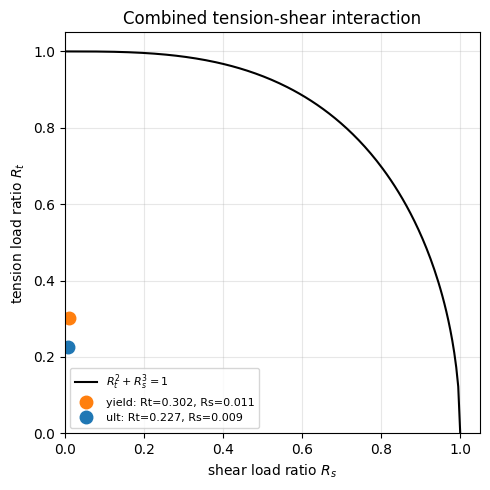

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
Rs_c = np.linspace(0, 1, 200)
ax.plot(Rs_c, np.sqrt(np.clip(1 - Rs_c**3, 0, None)), "k-", label="$R_t^2+R_s^3=1$")

for basis, colour in (("yield", "tab:orange"), ("ult", "tab:blue")):
    Rt, Rs = M.load_ratios(analysis.P_b, load_case.V, fastener, bolt_mat,
                           basis, load_case.SF_shear, SHEAR_PLANE_IN_SHANK)
    ax.plot(Rs, Rt, "o", color=colour, ms=9, label=f"{basis}: Rt={Rt:.3f}, Rs={Rs:.3f}")
    tm = M.combined_margin(Rt, Rs, basis, method="tm106943").MS
    gl = M.combined_margin(Rt, Rs, basis, method="guideline").MS
    print(f"{basis:>6}:  MS(TM-106943) = {tm:7.3f}    MOS(Guideline) = {gl:7.3f}")

ax.set_xlabel("shear load ratio $R_s$"); ax.set_ylabel("tension load ratio $R_t$")
ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.05); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("Combined tension-shear interaction")
plt.tight_layout(); plt.show()

## 5.3 Layer-by-layer member stiffness

`STIFFNESS_METHOD = "frustum"` builds the clamped stack from Shigley stress
cones (Guideline sec. 5.2, eq. 18) rather than one closed-form expression with
an equivalent modulus.

Cones start at both bearing faces and expand at 30 deg toward the joint
midplane, so the stack is split at every material boundary **and** at the
midplane — symmetric frusta are required for equilibrium, and each layer's
start diameter must account for the cone that preceded it. The individual
stiffnesses combine in series.

For a threaded hole the far bearing face is taken at the midpoint of the
engaged threads, which is how the effective thicknesses are already computed.

In [8]:
frusta = joint.layer_stiffnesses()
fr = pd.DataFrame([{
    "layer": f.index + 1,
    "x start [in]": f.x_start,
    "t [in]": f.thickness,
    "d start [in]": f.d_start,
    "E [psi]": f.E,
    "k_i [lbf/in]": f.k,
    "compliance [in/lbf]": f.compliance,
} for f in frusta])
display(fr.style.format({
    "x start [in]": "{:.4f}", "t [in]": "{:.4f}", "d start [in]": "{:.4f}",
    "E [psi]": "{:,.0f}", "k_i [lbf/in]": "{:,.0f}",
    "compliance [in/lbf]": "{:.3e}"}).hide(axis="index"))

print(f"series total kj = {joint.kj:,.0f} lbf/in")
print(f"softest frustum = {min(f.k for f in frusta):,.0f} lbf/in "
      f"(layer {min(frusta, key=lambda f: f.k).index + 1})")

# how much does the method choice actually move the answer?
alt = "tm106943" if STIFFNESS_METHOD == "frustum" else "frustum"
joint_alt = Joint(fastener, layers, bolt_mat, configuration=CONFIGURATION,
                  insert_length=Li, stiffness_method=alt,
                  washer_face_dia=WASHER_FACE_DIA, cone_angle_deg=CONE_ANGLE_DEG)
pd.DataFrame([
    {"method": STIFFNESS_METHOD, "kj [lbf/in]": joint.kj, "phi": joint.phi},
    {"method": alt, "kj [lbf/in]": joint_alt.kj, "phi": joint_alt.phi},
])

layer,x start [in],t [in],d start [in],E [psi],k_i [lbf/in],compliance [in/lbf]
1,0.0000,0.0600,0.1400,"9,900,000","2,767,037",3.614e-07
2,0.0600,0.0023,0.2093,"9,900,000","127,677,072",7.832e-09
2,0.0622,0.0622,0.1400,"9,900,000","2,708,342",3.692e-07


series total kj = 1,354,171 lbf/in
softest frustum = 2,708,342 lbf/in (layer 2)


,method,kj [lbf/in],phi
0,frustum,"1,354,170.8163",0.3895
1,tm106943,"2,333,364.1042",0.2702


### 5.4 Thermal load, layer by layer

Guideline sec. 7. Each layer expands freely by `alpha_i * l_i * dT`; the bolt
by `alpha_b * L * dT`. Compatibility (eq. 31) forces the difference through the
bolt and member springs in series:

$$P_{th} = \frac{\Delta T \left( \sum_i \alpha_i l_i - \alpha_b L \right)}{1/k_b + 1/k_j}$$

This collapses to the TM-106943 single-CTE form when the weighted sum is
written as `alpha_eq * L`. What the layer-by-layer treatment actually buys you
is a `k_j` built from real per-layer stiffnesses, and visibility into which
layer drives the mismatch.

In [9]:
for case, dT in environment.cases.items():
    if dT == 0:
        continue
    res = joint.thermal_breakdown(dT)
    print(f"--- {case}: dT = {dT:+.1f} F ---")
    print(f"  free expansion, joint : {res.free_expansion_joint:+.6f} in")
    print(f"  free expansion, bolt  : {res.free_expansion_bolt:+.6f} in")
    print(f"  mismatch              : {res.mismatch:+.6f} in")
    print(f"  P_thermal             : {res.P_thermal:+.2f} lbf\n")

joint.thermal_breakdown(environment.cases["cold"]).to_dataframe().style.format({
    "thickness [in]": "{:.4f}", "d_start [in]": "{:.4f}", "E [psi]": "{:,.0f}",
    "alpha [ppm/F]": "{:.2f}", "k_i [lbf/in]": "{:,.0f}",
    "free expansion [in]": "{:.3e}", "constrained defl [in]": "{:.3e}"}).hide(axis="index")

--- hot: dT = +91.8 F ---
  free expansion, joint : +0.000150 in
  free expansion, bolt  : +0.000105 in
  mismatch              : +0.000045 in
  P_thermal             : +23.69 lbf

--- cold: dT = -81.0 F ---
  free expansion, joint : -0.000132 in
  free expansion, bolt  : -0.000092 in
  mismatch              : -0.000040 in
  P_thermal             : -20.90 lbf



layer,material,thickness [in],d_start [in],E [psi],alpha [ppm/F],k_i [lbf/in],free expansion [in],constrained defl [in]
1,Aluminum 6061-T6,0.0600,0.1400,"9,900,000",13.10,"2,767,037",-6.367e-05,7.555e-06
2,Aluminum 6061-T6,0.0023,0.2093,"9,900,000",13.10,"127,677,072",-2.387e-06,1.637e-07
2,Aluminum 6061-T6,0.0622,0.1400,"9,900,000",13.10,"2,708,342",-6.605e-05,7.718e-06


## 5.5 Hot and cold envelope

Each check sees the temperature that hurts it. A tensile thermal load adds to
**maximum** preload for bolt strength; a preload-relieving thermal load
subtracts from **minimum** preload for separation. One temperature cannot drive
both, so both extremes must be run — this is the NASA convention adopted by the
Guideline in sec. 7.

Expect the hot case to govern bolt tension and the cold case to govern
separation whenever the stack expands more than the bolt.

In [10]:
envelope = run_thermal_envelope(fastener, bolt_mat, joint, preload, load_case,
                                environment, insert=insert, abutment=abutment,
                                shear_plane_in_shank=SHEAR_PLANE_IN_SHANK)
print(envelope.report())
display(envelope.thermal_loads())

Thermal envelope
ambient   dT =    +0.0 F   P_th =    +0.00 lbf   P_b =   110.44 lbf   MS =   2.877  (head/washer bearing)
hot       dT =   +91.8 F   P_th =   +23.69 lbf   P_b =   134.13 lbf   MS =   2.192  (head/washer bearing)
cold      dT =   -81.0 F   P_th =   -20.90 lbf   P_b =   110.44 lbf   MS =   2.877  (head/washer bearing)
--------------------------------------------------------------
Governing: head/washer bearing (yield) in the hot case, MS = 2.192
PASS


,case,dT [F],P_thermal [lbf],P_b [lbf],governing mode,governing MS
0,ambient,0.0000,0.0000,110.4406,head/washer bearing,2.8769
1,hot,91.8000,23.6908,134.1313,head/washer bearing,2.1922
2,cold,-81.0000,-20.9036,110.4406,head/washer bearing,2.8769


In [11]:
env_df = envelope.envelope()

def _flag(row):
    style = "background-color: #f8d7da" if not row["pass"] else ""
    return [style for _ in row]

display(env_df.style.apply(_flag, axis=1).format({"MS": "{:,.3f}"}))

driving = env_df.groupby("case").size()
print("\nModes driven by each case:")
print(driving.to_string())

,mode,basis,case,MS,pass
0,head/washer bearing,yield,hot,2.192,True
1,combined tension+shear,yield,hot,2.307,True
2,bolt tension,yield,hot,2.307,True
3,combined tension+shear,ult,hot,3.409,True
4,bolt tension,ult,hot,3.409,True
5,joint separation,n/a,cold,6.166,True
6,parent internal thread shear,ult,hot,6.224,True
7,insert internal thread shear,ult,hot,7.039,True
8,insert external thread shear,ult,hot,9.750,True
9,bolt thread shear,ult,hot,10.079,True



Modes driven by each case:
case
ambient    6
cold       1
hot        9


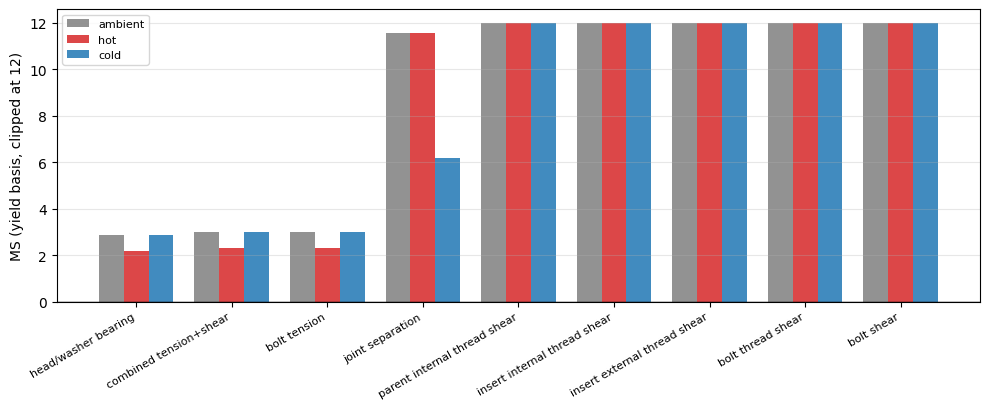

In [12]:
# margin per mode across the three temperature cases
modes = [m for m in env_df["mode"].unique()][:9]
fig, ax = plt.subplots(figsize=(10, 4.2))
width = 0.26
x = np.arange(len(modes))
for k, (case, colour) in enumerate((("ambient", "tab:grey"),
                                    ("hot", "tab:red"),
                                    ("cold", "tab:blue"))):
    by = {(r.mode): r.MS for r in envelope.cases[case].results if r.basis != "ult"}
    vals = [min(by.get(m, np.inf), 12) for m in modes]
    ax.bar(x + (k - 1) * width, vals, width, label=case, color=colour, alpha=.85)
ax.axhline(0, color="k", lw=1)
ax.set_xticks(x); ax.set_xticklabels(modes, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("MS (yield basis, clipped at 12)"); ax.legend(fontsize=8)
ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

## 6. Sensitivity

How much external load the joint tolerates before the governing margin goes
negative. Far more useful than a single-point answer when sizing.


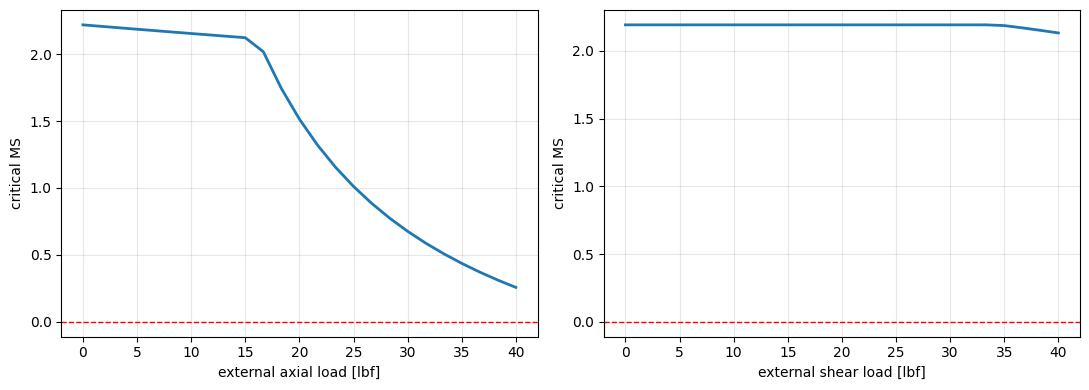

positive margin across the entire swept axial range


In [13]:
def sweep(values, attr):
    rows = []
    for v in values:
        lc = LoadCase(**{**load_case.__dict__, attr: v})
        a = JointAnalysis(fastener, bolt_mat, joint, preload, lc,
                          insert=insert, abutment=abutment,
                          shear_plane_in_shank=SHEAR_PLANE_IN_SHANK)
        rows.append({attr: v, "critical MS": a.critical.MS, "mode": a.critical.mode})
    return pd.DataFrame(rows)

axial = sweep(np.linspace(0, max(4 * P_ET, 40), 25), "P_et")
shear = sweep(np.linspace(0, max(4 * V_SHEAR, 40), 25), "V")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, col, lbl in ((axes[0], axial, "P_et", "external axial load [lbf]"),
                        (axes[1], shear, "V", "external shear load [lbf]")):
    ax.plot(d[col], d["critical MS"], lw=2)
    ax.axhline(0, color="r", ls="--", lw=1)
    ax.set_xlabel(lbl); ax.set_ylabel("critical MS"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

ok = axial[axial["critical MS"] >= 0]["P_et"]
print(f"largest swept axial load with a positive margin: {ok.max():.1f} lbf"
      if len(ok) < len(axial) else
      "positive margin across the entire swept axial range")

## 7. Preload sensitivity

Bolt strength and separation pull in opposite directions: more preload protects
against separation and hurts bolt tension. This shows the usable window.


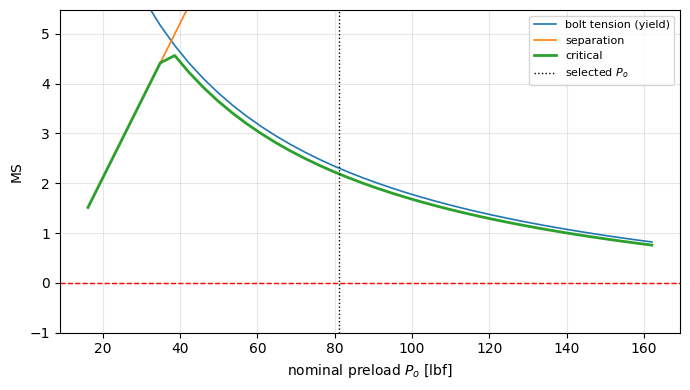

In [14]:
rows = []
for Po in np.linspace(0.2 * preload.Po, 2.0 * preload.Po, 40):
    p = Preload(Po=Po, u=preload.u, relax=preload.relax,
                K=preload.K, d_major=preload.d_major)
    a = JointAnalysis(fastener, bolt_mat, joint, p, load_case,
                      insert=insert, abutment=abutment,
                      shear_plane_in_shank=SHEAR_PLANE_IN_SHANK)
    byname = {(r.mode, r.basis): r.MS for r in a.results}
    rows.append({"Po": Po,
                 "bolt tension (yield)": byname[("bolt tension", "yield")],
                 "separation": byname[("joint separation", "n/a")],
                 "critical": a.critical.MS})
sens = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for c in ("bolt tension (yield)", "separation", "critical"):
    ax.plot(sens["Po"], sens[c], label=c, lw=2 if c == "critical" else 1.2)
ax.axhline(0, color="r", ls="--", lw=1)
ax.axvline(preload.Po, color="k", ls=":", lw=1, label="selected $P_o$")
ax.set_xlabel("nominal preload $P_o$ [lbf]"); ax.set_ylabel("MS")
ax.set_ylim(-1, min(10, sens["critical"].max() * 1.2)); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Assembly summary

In [15]:
summary = {
    "Fastener": f"{THREAD} {HEAD_STYLE}, {bolt_mat.name}",
    "Quantity": NUMBER_OF_BOLTS,
    "Nominal torque [lbf-in]": round(preload.torque_nominal, 3),
    "Torque range [lbf-in]": f"{t_lo:.3f} - {t_hi:.3f}",
    "Nominal preload [lbf]": round(preload.Po, 1),
    "Total clamp force [lbf]": round(preload.Po * NUMBER_OF_BOLTS, 1),
    "Bolt axial load P_b [lbf]": round(analysis.P_b, 2),
    "Thermal load [lbf]": round(analysis.P_thermal, 2),
    "Governing mode": f"{analysis.critical.mode} ({analysis.critical.basis})",
    "Governing MS": round(analysis.critical.MS, 3),
    "Verdict": "PASS" if analysis.passes else "FAIL",
}
pd.Series(summary).to_frame("value")

,value
Fastener,"2-56 socket, A286 fastener (AMS 5731/5737, 160..."
Quantity,7
Nominal torque [lbf-in],1.3930
Torque range [lbf-in],0.906 - 1.881
Nominal preload [lbf],81.0000
Total clamp force [lbf],567.0000
Bolt axial load P_b [lbf],134.1300
Thermal load [lbf],23.6900
Governing mode,head/washer bearing (yield)
Governing MS,2.1920


## 9. Verification

Run the regression suite before trusting any result. Each `revb` test pins one
of the defects listed in the table at the top.


In [16]:
import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "../tests", "-q"],
                     capture_output=True, text=True).stdout[-1200:])


==================================== ERRORS ====================================
___________________ ERROR collecting tests/test_boltjoint.py ___________________
ImportError while importing test module '/home/claude/work/boltjoint_proj/tests/test_boltjoint.py'.
Hint: make sure your test modules/packages have valid Python names.
Traceback:
/usr/lib/python3.12/importlib/__init__.py:90: in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
../tests/test_boltjoint.py:7: in <module>
    from boltjoint import (
E   ModuleNotFoundError: No module named 'boltjoint'
=========================== short test summary info ============================
ERROR ../tests/test_boltjoint.py
!!!!!!!!!!!!!!!!!!!! Interrupted: 1 error during collection !!!!!!!!!!!!!!!!!!!!
1 error in 0.23s



## 10. Limitations

- The combined-load margins (TM-106943 eqs. 59/62) can be **unconservative** for
  shear-critical joints. TM-106943 explicitly cautions that its equations assume
  shear is small relative to the axial load. Check the interaction curve directly
  when margins are below ~0.5, and use Bruhn / NASA TM X-73305 for tear-out and
  bearing when `e/D < 1.5` or margins are marginal.
- Material properties in `boltjoint/materials.py` are **typical values for
  convenience only**. Replace them with MMPDS / the applicable material and
  fastener procurement specification before releasing any analysis.
- Bearing allowables default to `1.5*Ftu` / `1.5*Fty`, a placeholder. Use real
  bearing data.
- Thermal treatment assumes a uniform temperature change and a
  thickness-weighted joint CTE. For dissimilar stacks with large CTE spread, use
  the layer-by-layer method of the Guideline sec. 7.
- Fatigue, self-loosening, creep of dielectrics, and gapping under bending are
  not covered.
- Single-fastener analysis. Load distribution across a pattern must be done
  upstream.
